In [1]:
#Accuracy

from sklearn.metrics import accuracy_score

y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 0, 1, 1, 1, 0]

accuracy = accuracy_score(y_true, y_pred)

print("Accuracy:", round(accuracy, 2))
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.8
Accuracy percentage: 80.0 %


In [3]:
#Precision

from sklearn.metrics import precision_score

y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 0, 1, 1, 1, 0]

precision = precision_score(y_true, y_pred)

print("Precision:", round(precision, 2))

Precision: 0.8


In [4]:
#Recall

from sklearn.metrics import recall_score

y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 0, 1, 1, 1, 0]

recall = recall_score(y_true, y_pred)

print("Recall:", round(recall, 2))

Recall: 0.8


In [5]:
#F1 Score

from sklearn.metrics import f1_score

y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 0, 1, 1, 1, 0]

print("F1-score:", round(f1_score(y_true, y_pred), 3))
print("Macro F1:", round(f1_score(
    y_true, y_pred, average="macro"
), 3))

F1-score: 0.8
Macro F1: 0.8


ROC-AUC: 1.0


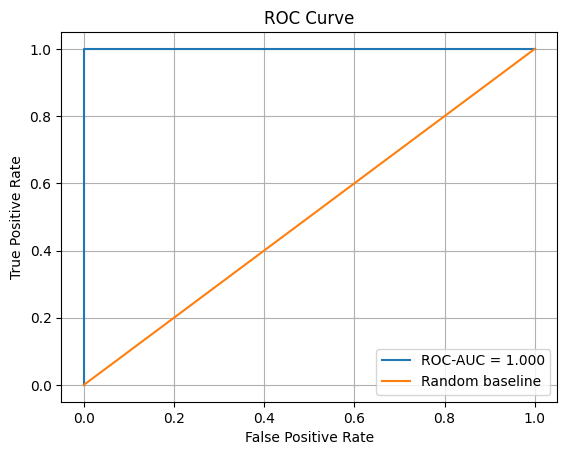

In [7]:
#ROC-AUC

import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score,
    roc_curve
)

y_true = [0, 0, 0, 1, 1, 1]
y_prob = [0.1, 0.4, 0.35, 0.8, 0.7, 0.95]

auc = roc_auc_score(y_true, y_prob)
fpr, tpr, thresholds = roc_curve(y_true, y_prob)

print("ROC-AUC:", round(auc, 3))

plt.plot(fpr, tpr, label=f"ROC-AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="-", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
#BLEU score

!pip -q install nltk

In [9]:
from nltk.translate.bleu_score import (
    sentence_bleu,
    SmoothingFunction
)

reference = ["the cat is sitting on the mat".split()]
candidate = "the cat is on the mat".split()

score = sentence_bleu(
    reference,
    candidate,
    smoothing_function=SmoothingFunction().method1
)

print("BLEU score:", round(score, 4))

BLEU score: 0.2876


In [10]:
#ROUGE score

!pip -q install rouge-score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [11]:
from rouge_score import rouge_scorer

reference = (
    "Artificial intelligence helps computers "
    "perform tasks that require human intelligence."
)

generated = (
    "AI helps computers perform tasks requiring "
    "human intelligence."
)

scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

scores = scorer.score(reference, generated)

for metric, score in scores.items():
    print(
        metric,
        "Precision:", round(score.precision, 3),
        "Recall:", round(score.recall, 3),
        "F1:", round(score.fmeasure, 3)
    )

rouge1 Precision: 0.875 Recall: 0.7 F1: 0.778
rouge2 Precision: 0.714 Recall: 0.556 F1: 0.625
rougeL Precision: 0.875 Recall: 0.7 F1: 0.778


In [12]:
#Build a small RAG evaluation dataset

dataset = [
    {
        "question": "What is RAG?",
        "reference": (
            "RAG combines information retrieval "
            "with language model generation."
        ),
        "context": [
            "RAG retrieves relevant documents and "
            "provides them to a language model."
        ],
        "answer": (
            "RAG combines document retrieval "
            "with language model generation."
        )
    },
    {
        "question": "What is supervised learning?",
        "reference": (
            "Supervised learning trains a model "
            "using labeled examples."
        ),
        "context": [
            "Supervised learning uses labeled "
            "training data."
        ],
        "answer": (
            "Supervised learning uses labeled "
            "examples to train a model."
        )
    }
]

for item in dataset:
    print("Question:", item["question"])
    print("Reference:", item["reference"])
    print("Retrieved context:", item["context"])
    print("Generated answer:", item["answer"])
    print("-" * 50)

Question: What is RAG?
Reference: RAG combines information retrieval with language model generation.
Retrieved context: ['RAG retrieves relevant documents and provides them to a language model.']
Generated answer: RAG combines document retrieval with language model generation.
--------------------------------------------------
Question: What is supervised learning?
Reference: Supervised learning trains a model using labeled examples.
Retrieved context: ['Supervised learning uses labeled training data.']
Generated answer: Supervised learning uses labeled examples to train a model.
--------------------------------------------------


In [13]:
#Simulate an agent evaluation dataset

import pandas as pd

runs = [
    {
        "task": "Find repository README",
        "success": 1,
        "tool_selection_correct": 1,
        "tool_calls": 2,
        "latency_seconds": 3.2,
        "cost_usd": 0.002
    },
    {
        "task": "Explain authentication",
        "success": 1,
        "tool_selection_correct": 1,
        "tool_calls": 3,
        "latency_seconds": 4.8,
        "cost_usd": 0.004
    },
    {
        "task": "Find database configuration",
        "success": 0,
        "tool_selection_correct": 0,
        "tool_calls": 6,
        "latency_seconds": 9.5,
        "cost_usd": 0.008
    },
    {
        "task": "Explain API routes",
        "success": 1,
        "tool_selection_correct": 1,
        "tool_calls": 2,
        "latency_seconds": 3.5,
        "cost_usd": 0.003
    }
]

df = pd.DataFrame(runs)

print("Task success rate:",
      round(df["success"].mean() * 100, 2), "%")

print("Tool selection accuracy:",
      round(df["tool_selection_correct"].mean() * 100, 2), "%")

print("Average tool calls:",
      round(df["tool_calls"].mean(), 2))

print("Average latency:",
      round(df["latency_seconds"].mean(), 2), "seconds")

print("Total estimated cost:",
      round(df["cost_usd"].sum(), 4), "USD")

display(df)

Task success rate: 75.0 %
Tool selection accuracy: 75.0 %
Average tool calls: 3.25
Average latency: 5.25 seconds
Total estimated cost: 0.017 USD


,task,success,tool_selection_correct,tool_calls,latency_seconds,cost_usd
0,Find repository README,1,1,2,3.2,0.002
1,Explain authentication,1,1,3,4.8,0.004
2,Find database configuration,0,0,6,9.5,0.008
3,Explain API routes,1,1,2,3.5,0.003
